# Intelligent Gomoku - Experimental Analysis

This notebook analyses the data produced by `benchmark.py` (AI vs AI experiments) and by human games recorded in `games/`. It answers the questions from the project synopsis:

1. How much does **alpha-beta pruning** and **move ordering** reduce the number of game states searched?
2. How do the agents (Random, Rule-Based, Minimax, Alpha-Beta, Expert) compare in **playing strength** and **decision time**?
3. What do the recorded **human games** tell us about common mistakes?

In [1]:
import os, glob
import pandas as pd
import matplotlib.pyplot as plt
ROOT = '..' if os.path.basename(os.getcwd()) == 'analysis' else '.'
R = os.path.join(ROOT, 'results')
eff = pd.read_csv(os.path.join(R, 'search_efficiency.csv'))
games = pd.read_csv(os.path.join(R, 'tournament_games.csv'))
moves = pd.read_csv(os.path.join(R, 'tournament_moves.csv'))
standings = pd.read_csv(os.path.join(R, 'standings.csv'))
print(f'{len(eff)} search measurements, {len(games)} tournament games, {len(moves)} recorded AI moves')

72 search measurements, 40 tournament games, 832 recorded AI moves


## 1. Search efficiency: Minimax vs Alpha-Beta

Every algorithm searched the **same test positions** with the **same candidate moves** and the same heuristic, so the only difference is pruning and move ordering.

In [2]:
pivot = eff.pivot_table(index='depth', columns='algorithm', values='nodes', aggfunc='mean').round(0)
pivot = pivot[['Minimax', 'Alpha-Beta (unordered)', 'Alpha-Beta (ordered)']]
pivot

algorithm,Minimax,Alpha-Beta (unordered),Alpha-Beta (ordered)
depth,,,
1,10.0,10.0,10.0
2,108.0,60.0,33.0
3,958.0,328.0,150.0


In [3]:
saving = (1 - pivot.div(pivot['Minimax'], axis=0)) * 100
print('States saved compared with plain minimax (%):')
saving.round(1)

States saved compared with plain minimax (%):


algorithm,Minimax,Alpha-Beta (unordered),Alpha-Beta (ordered)
depth,,,
1,0.0,0.0,0.0
2,0.0,44.4,69.4
3,0.0,65.8,84.3


In [4]:
t = eff.pivot_table(index='depth', columns='algorithm', values='time_ms', aggfunc='mean').round(1)
print('Average time per decision (ms):')
t[['Minimax', 'Alpha-Beta (unordered)', 'Alpha-Beta (ordered)']]

Average time per decision (ms):


algorithm,Minimax,Alpha-Beta (unordered),Alpha-Beta (ordered)
depth,,,
1,5.5,5.5,5.9
2,67.9,54.5,51.3
3,1744.2,862.3,521.1


In [5]:
agree = eff.groupby('depth')['same_value_as_minimax'].mean() * 100
print('Positions where all three algorithms returned the same minimax value (%):')
print(agree.to_string())

Positions where all three algorithms returned the same minimax value (%):
depth
1    100.0
2    100.0
3    100.0


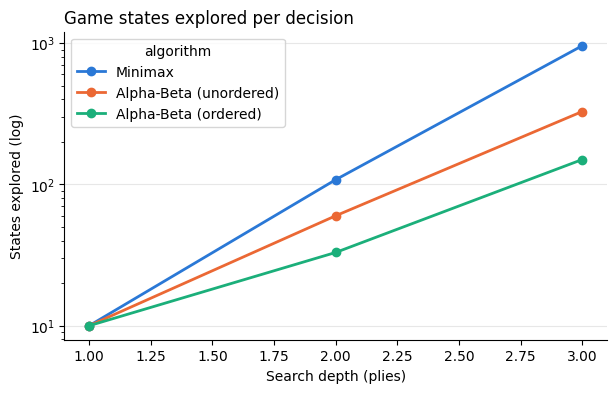

In [6]:
colors = {'Minimax': '#2a78d6', 'Alpha-Beta (unordered)': '#eb6834', 'Alpha-Beta (ordered)': '#1baf7a'}
ax = pivot.plot(marker='o', logy=True, figsize=(7, 4), color=[colors[c] for c in pivot.columns], linewidth=2)
ax.set_xlabel('Search depth (plies)'); ax.set_ylabel('States explored (log)')
ax.set_title('Game states explored per decision', loc='left')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=.3)
plt.show()

**Observation.** Alpha-beta returns exactly the same value as minimax (the agreement check above) while visiting far fewer states, and the saving grows with depth. Good move ordering (searching wins, blocks and strong threats first) multiplies the effect, which is why the ordered version is the one used by the Hard and Expert levels.

## 2. Tournament: playing strength vs computational cost

In [7]:
standings.set_index('agent')

,played,wins,draws,losses,win_rate,avg_ms_per_move,avg_states_per_move
agent,,,,,,,
Alpha-Beta d3,16,12,0,4,0.750,271.1,143.2
Expert,16,12,0,4,0.750,802.4,459.8
Rule-Based,16,9,0,7,0.562,32.2,68.8
Minimax d2,16,7,0,9,0.438,94.0,81.7
Random,16,0,0,16,0.000,0.1,219.9


In [8]:
def score(row_agent, col_agent):
    g = games[((games.black == row_agent) & (games.white == col_agent)) |
              ((games.black == col_agent) & (games.white == row_agent))]
    if g.empty: return None
    pts = (g.winner_agent == row_agent).sum() + 0.5 * (g.winner_agent == 'Draw').sum()
    return round(100 * pts / len(g))
names = list(standings.agent)
h2h = pd.DataFrame({c: [score(r, c) if r != c else None for r in names] for c in names}, index=names)
print('Head-to-head score % (row agent vs column agent):')
h2h

Head-to-head score % (row agent vs column agent):


,Alpha-Beta d3,Expert,Rule-Based,Minimax d2,Random
Alpha-Beta d3,NaN,50.0,75.0,75.0,100.0
Expert,50.0,NaN,50.0,100.0,100.0
Rule-Based,25.0,50.0,NaN,50.0,100.0
Minimax d2,25.0,0.0,50.0,NaN,100.0
Random,0.0,0.0,0.0,0.0,NaN


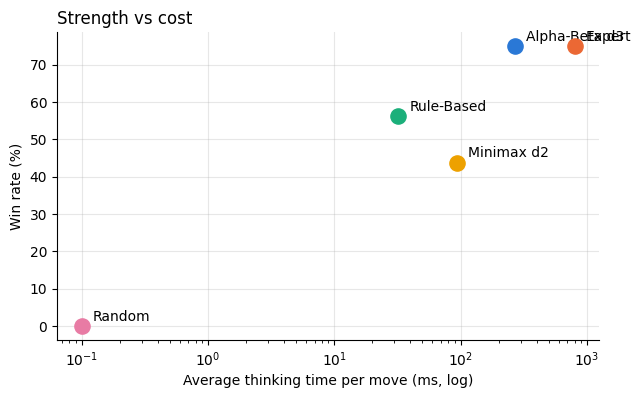

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
palette = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
for i, r in standings.iterrows():
    ax.scatter(max(r.avg_ms_per_move, 0.05), r.win_rate * 100, s=120, color=palette[i % 5], zorder=3)
    ax.annotate(r.agent, (max(r.avg_ms_per_move, 0.05), r.win_rate * 100), xytext=(8, 4), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('Average thinking time per move (ms, log)'); ax.set_ylabel('Win rate (%)')
ax.set_title('Strength vs cost', loc='left'); ax.spines[['top', 'right']].set_visible(False); ax.grid(alpha=.3)
plt.show()

In [10]:
games['pairing'] = games[['black', 'white']].apply(lambda r: ' vs '.join(sorted(r)), axis=1)
print('Average game length (moves) by pairing:')
games.groupby('pairing')['moves'].mean().sort_values().round(1)

Average game length (moves) by pairing:


pairing
Minimax d2 vs Random            9.5
Expert vs Random                9.5
Random vs Rule-Based            9.5
Alpha-Beta d3 vs Random        10.5
Alpha-Beta d3 vs Minimax d2    24.8
Alpha-Beta d3 vs Expert        27.0
Expert vs Minimax d2           28.0
Expert vs Rule-Based           32.0
Alpha-Beta d3 vs Rule-Based    35.8
Minimax d2 vs Rule-Based       41.5
Name: moves, dtype: float64

In [11]:
print('Why the agents moved (top reasons per agent):')
moves.groupby('agent')['reason'].value_counts().groupby(level=0).head(4)

Why the agents moved (top reasons per agent):


agent       reason                             
Alpha-Beta  Creates a double open three (fork)     39
            Creates a four (forcing move)          31
            Blocks opponent's five                 20
            Builds own shape                       20
Expert      Creates a double open three (fork)     31
            Blocks opponent's five                 29
            Blocks opponent's open three           26
            Creates a four (forcing move)          26
Minimax     Blocks opponent's open three           32
            Creates a four (forcing move)          32
            Restricts opponent's development       30
            Blocks opponent's five                 27
Random      Random legal move                      58
Rule-Based  Rule 6: best attack + defence value    60
            Rule 2: block opponent's five          59
            Rule 5: block opponent's open three    55
            Rule 4: create a double three          25
Name: count, dtype: int64

In [12]:
print('States explored per move as the game progresses (Alpha-Beta and Expert):')
sub = moves[moves.agent.isin(['Alpha-Beta', 'Expert'])].copy()
sub['phase'] = pd.cut(sub.move_no, [0, 10, 20, 30, 225], labels=['1-10', '11-20', '21-30', '31+'])
sub.pivot_table(index='phase', columns='agent', values='nodes', aggfunc='mean', observed=False).round(0)

States explored per move as the game progresses (Alpha-Beta and Expert):


agent,Alpha-Beta,Expert
phase,,
1-10,189.0,793.0
11-20,132.0,493.0
21-30,115.0,170.0
31+,87.0,18.0


## 3. Human games recorded by the GUI

Every finished Single-Player game is saved to `games/` with the rule-based coach's labels per move.

In [13]:
rows = []
for f in sorted(glob.glob(os.path.join(ROOT, 'games', 'game_*.csv'))):
    meta = pd.read_csv(f, nrows=1)
    mv = pd.read_csv(f, skiprows=3)
    mv['file'] = os.path.basename(f); mv['mode'] = meta['mode'][0]; mv['winner'] = meta['winner'][0]
    rows.append(mv)
human = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
summary = human.groupby('file').agg(mode=('mode', 'first'), winner=('winner', 'first'), moves=('move_no', 'max'))
print(f'{len(summary)} recorded games')
summary.groupby(['mode', 'winner']).size().rename('games')

27 recorded games


mode              winner  
player_vs_player  Player 2     1
single_player     Computer    14
                  You         12
Name: games, dtype: int64

In [14]:
flags = ['good_move', 'missed_win', 'missed_block', 'weak_edge', 'low_value', 'risky_move', 'forced_move']
flags = [f for f in flags if f in human.columns]
print('How often each label appears in the analysed (human) moves:')
(human[flags].apply(pd.to_numeric, errors='coerce').fillna(0).sum()
 .sort_values(ascending=False).rename('count'))

How often each label appears in the analysed (human) moves:


good_move       25
forced_move     11
missed_block     9
weak_edge        8
missed_win       5
low_value        3
risky_move       2
Name: count, dtype: int64

## 4. A dataset for machine learning

`results/tournament_moves.csv` stores, for every AI move, the full board after the move (`board_after`, 225 characters), who moved, the search statistics and the reason. This is the starting point for the future ML coaching described in the synopsis, e.g. learning to predict the strong agent's move from the board.

In [15]:
import numpy as np
def board_to_array(s):
    return np.array([0 if ch == '.' else (1 if ch == 'b' else -1) for ch in s]).reshape(15, 15)
X = np.stack([board_to_array(s) for s in moves.board_after])
print('Feature tensor:', X.shape, '| labels (move cell):', moves[['row', 'col']].shape)

Feature tensor: (832, 15, 15) | labels (move cell): (832, 2)


## Conclusion

* **Uninformed vs informed search.** The Random agent never wins; adding domain knowledge (rules, then a heuristic evaluation) is what makes an agent play well.
* **Alpha-beta pruning** gives the same decisions as minimax while exploring a fraction of the states; with move ordering the saving is even larger, which allows deeper search in the same time.
* **Iterative deepening + transposition table** (Expert) searches deeper within its time budget (about 3x more states per move than fixed depth 3), but in this tournament it only tied with Alpha-Beta depth 3. Deeper search does not automatically mean stronger play: the heuristic's quality and the candidate cut-off limit what extra depth can find. This is a direction for future work.
* The recorded games give a growing dataset for coaching and machine-learning extensions.